# Robust-ASR : Transformer hybride CTC / attention sur LibriSpeech

Ce notebook implémente de bout en bout une chaîne de reconnaissance vocale robuste au bruit
et à la réverbération, de la forme d'onde à la transcription.

```
Audio 16 kHz
  │                          ◄── [train] vitesse, RIR, bruit MUSAN ou babble, sur la forme d'onde
Log-Mel (80 bandes, 25 ms)
  │                          ◄── [train] SpecAugment
Frontend CNN (2 Conv2d, sous-échantillonnage ×4)
  │
Encodeur Transformer (12 couches, d=256)
  ├── Tête CTC (linéaire + softmax) ─┐
  └── Décodeur (6 couches) ──────────┤ ──► [train] loss = 0.3 CTC + 0.7 CE
                                     ▼
                      Beam search joint CTC / attention
                                     │
                      LM / correction d'erreurs (optionnel, indépendant)
                                     ▼
                               Transcription
```

## Répartition des données

| | Train | Validation | Test |
|---|---|---|---|
| **Parole** | `train-clean-100`, `train-clean-360`, `train-other-500` (960 h) | `dev-clean`, `dev-other` | `test-clean`, `test-other` |
| **RIR** | OpenSLR 26 simulées, p = 0.3, tirée à chaque chargement | Salles simulées réservées, p = 0.3, figé (`val_v2`) | Réelles (OpenSLR 28, ACE), figé |
| **MUSAN** | 80 % des fichiers, `noise` et `music` (tirage ci-dessous) | 20 % des fichiers mis de côté, `noise` et `music`, figé (`val_v2`) | Non utilisé |
| **Babble** | 3 à 7 énoncés LibriSpeech du train (tirage ci-dessous) | 3 à 7 énoncés de `dev-clean` et `dev-other`, figé (`val_v2`) | Non utilisé |
| **SpecAugment** | Toujours : 2 masques fréq. (F ≤ 27), 2 masques temps (T ≤ 40) | Jamais | Jamais |
| **WHAM!** | Jamais | Jamais | Split `tt`, SNR ∈ {−5, 0, 5, 10, 20} dB, figé |
| **DEMAND** | Jamais | Jamais | SNR ∈ {−5, 0, 5, 10, 20} dB, figé |

À l'entraînement, le bruit s'applique avec p = 0.6 et se tire en deux étages : la catégorie, puis un
fichier de cette catégorie, pondéré par la racine carrée de sa durée. L'exposant 1 donnerait à chaque
seconde la même chance, mais concentrerait les tirages sur quelques longs fichiers : le modèle verrait
surtout des segments différents des mêmes enregistrements.

| Catégorie | Probabilité | SNR à l'entraînement | SNR en validation |
|---|---|---|---|
| Noise (MUSAN) | 0.4 | U(0, 15) dB | {0, 5, 10} dB |
| Music (MUSAN) | 0.3 | U(5, 15) dB | {5, 10, 15} dB |
| Babble (LibriSpeech, 3 à 7 locuteurs) | 0.3 | U(13, 20) dB | {13, 17, 20} dB |

Chaque catégorie a son SNR, car la musique et surtout le babble, proches de la parole, gênent bien
plus qu'un bruit stationnaire au même SNR. Les SNR de validation restent dans la plage d'entraînement
de chaque catégorie : la validation sélectionne un modèle, l'extrapolation revient au test. Le test est
évalué sur la parole propre **et** sur chaque condition dégradée ; la validation est décrite en section 11.

**La validation est figée et indépendante de cette configuration.** `build_val_set.py` a sa propre
configuration et écrit une fois pour toutes, pour chaque énoncé, la RIR, les fichiers de bruit, leurs
offsets, la condition et le SNR. Le notebook relit ce fichier sans rien tirer : une ablation sur
l'exposant, `p_rir`, les probabilités ou la graine ne change pas les données de validation, et les runs
restent comparables. Les salles RIR réservées y sont aussi inscrites, et retirées du train quelle que
soit la graine. Pour changer la validation, il faut créer une nouvelle version et y réévaluer les
checkpoints à comparer.

## Choix d'implémentation

- **MUSAN** est partagé par `split_musan.py` : 80/20 par fichier, stratifié par (catégorie, source),
  à graine fixe. `speech/librivox` est exclu, car LibriSpeech provient de LibriVox : il pourrait
  partager des locuteurs et des textes avec la parole. Le détail est dans
  `data/manifests/musan/musan_split_summary.md`. `speech/us-gov` reste dans les manifestes, mais
  n'appartient à aucune catégorie : il ne sert ni à l'entraînement ni à la validation.
- **« Figé, graine fixe »** : au lieu d'écrire des gigaoctets d'audio dégradé, on n'écrit que les choix
  faits (validation), ou on les fait par un générateur dont la graine dérive de l'identifiant de
  l'énoncé (test). Le résultat est identique à chaque évaluation, et un même énoncé garde le même
  segment de bruit à tous les SNR.
- **Ordre sur la forme d'onde** : vitesse, puis RIR, puis bruit. Le locuteur est modifié d'abord, la
  salle ensuite, et le bruit s'ajoute au signal capté par le micro.
- **Vitesse** : tirée dans {0.9, 1.0, 1.1}, par rééchantillonnage. Elle ne figure pas dans le tableau
  de répartition mais dans le schéma d'architecture.
- **Tokens** : caractères, sans modèle de tokenisation à entraîner.
- **Non implémenté** : les corpus de test VOiCES et EARS.

## Prérequis

```bash
python download_librispeech.py   # environ 60 Go
python download_noise.py         # MUSAN, RIR, WHAM!, DEMAND, ACE
python split_musan.py            # partage train/validation de MUSAN
python build_val_set.py          # jeu de validation figé val_v2, une seule fois
```

In [22]:
import json
import math
import os
import random
import time
import zlib
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from pathlib import Path

# Lu à la première allocation CUDA : un kernel qui a déjà utilisé le GPU l'ignore, il faut le redémarrer.
os.environ.setdefault("PYTORCH_ALLOC_CONF", "expandable_segments:True")

import jiwer
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein
from torch.utils.data import DataLoader, Dataset, Sampler
from tqdm import tqdm

from src.augment.babble import BabbleBank
from src.augment.noise_mix import NoiseCategory, NoiseSampler, read_segment
from src.augment.val_set import NO_NOISE, category_wers, grid_summary_wer, load_val_set, render_noise

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Les formes changent à chaque batch : benchmark rechercherait l'algorithme à chaque fois (débit divisé par 2.3).
torch.backends.cudnn.benchmark = False
print(f"Périphérique : {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'}")

Périphérique : NVIDIA GeForce RTX 5060 Ti


## 1. Configuration

In [23]:
@dataclass
class Config:
    data_dir: Path = Path("data")
    ckpt_dir: Path = Path("checkpoints")
    seed: int = 1234

    # Parole : affectations officielles de LibriSpeech
    train_subsets: tuple = ("train-clean-100", "train-clean-360", "train-other-500")
    val_subsets: tuple = ("dev-clean", "dev-other")
    test_subsets: tuple = ("test-clean", "test-other")

    # Log-Mel : 80 bandes, fenêtre de 25 ms, pas de 10 ms
    sample_rate: int = 16_000
    n_mels: int = 80
    n_fft: int = 512
    win_length: int = 400
    hop_length: int = 160

    # Dégradations sur la forme d'onde
    p_rir: float = 0.3
    p_noise: float = 0.6
    noise_categories: tuple = (
        NoiseCategory("noise", probability=0.4, snr_db=(0.0, 15.0)),
        NoiseCategory("music", probability=0.3, snr_db=(5.0, 15.0)),
        NoiseCategory("babble", probability=0.3, snr_db=(13.0, 20.0)),
    )
    noise_duration_exponent: float = 0.5  # 1 : par seconde, 0.5 : racine carrée, 0 : par fichier
    test_snrs_db: tuple = (-5, 0, 5, 10, 20)
    speed_factors: tuple = (0.9, 1.0, 1.1)

    # SpecAugment
    freq_masks: int = 2
    freq_mask_width: int = 27
    time_masks: int = 2
    time_mask_width: int = 40

    # Modèle
    d_model: int = 256
    n_heads: int = 4
    d_ffn: int = 2048
    encoder_layers: int = 12
    decoder_layers: int = 6
    conv_channels: int = 32
    dropout: float = 0.1
    qk_norm: bool = True  # q et k normalisés par tête : borne les logits d'attention (section 8)

    # Loss hybride
    ctc_weight: float = 0.3
    label_smoothing: float = 0.1

    # Entraînement
    epochs: int = 60
    peak_lr: float = 1e-3
    warmup_steps: int = 15_000
    weight_decay: float = 1e-6
    grad_clip: float = 5.0
    max_skipped_in_a_row: int = 100  # pas sautés d'affilée (gradient non fini) avant l'arrêt
    divergence_ratio: float = 1.5  # arrêt si WER_sel dépasse ce multiple du meilleur
    max_batch_seconds: float = 800.0  # taille × durée max du batch
    num_workers: int = min(10, (os.cpu_count() or 2) - 2)

    # Évaluation
    val_set: str = "val_v2"  # jeu figé, indépendant des réglages ci-dessus
    eval_batch_seconds: float = 1500.0
    full_val_every: int = 10  # grille complète de diagnostic, toutes les N époques
    beam_size: int = 10
    beam_batch_seconds: float = 300.0
    use_corrector: bool = False


cfg = Config()
cfg.ckpt_dir.mkdir(parents=True, exist_ok=True)

random.seed(cfg.seed)
np.random.seed(cfg.seed)
torch.manual_seed(cfg.seed)


def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=device.type == "cuda")


def make_pad_mask(lengths, max_length):
    """True sur les positions de padding : (B, max_length)."""
    return torch.arange(max_length, device=lengths.device)[None] >= lengths[:, None]

## 2. Tokenizer

Les transcriptions de LibriSpeech n'utilisent que A-Z, l'apostrophe et l'espace. Le blank CTC occupe
l'indice 0, et le dernier indice sert à la fois de début et de fin de séquence pour le décodeur.

In [24]:
class CharTokenizer:
    def __init__(self):
        self.chars = " 'ABCDEFGHIJKLMNOPQRSTUVWXYZ"
        self.char_to_id = {char: index + 1 for index, char in enumerate(self.chars)}
        self.blank = 0
        self.sos = self.eos = len(self.chars) + 1
        self.vocab_size = len(self.chars) + 2

    def encode(self, text):
        return torch.tensor([self.char_to_id[char] for char in text], dtype=torch.long)

    def decode(self, ids):
        return "".join(self.chars[index - 1] for index in ids if self.blank < index < self.eos)


tok = CharTokenizer()

## 3. Manifestes de parole

`torchaudio.load` repose désormais sur `torchcodec` : `LIBRISPEECH` sert donc à énumérer les énoncés
(`get_metadata`), et `soundfile` à lire l'audio. Le premier appel lit l'en-tête de chaque fichier pour
connaître sa durée, puis le résultat est mis en cache dans `data/manifests/`.

In [25]:
def build_manifest(subset):
    cache = cfg.data_dir / "manifests" / f"{subset}.json"
    if cache.exists():
        return json.loads(cache.read_text())

    dataset = torchaudio.datasets.LIBRISPEECH(cfg.data_dir, url=subset, download=False)

    def describe(index):
        relative_path, _, text, speaker, chapter, utterance = dataset.get_metadata(index)
        path = cfg.data_dir / "LibriSpeech" / relative_path
        return {
            "id": f"{speaker}-{chapter}-{utterance:04d}",
            "path": str(path),
            "frames": sf.info(path).frames,
            "text": text,
        }

    with ThreadPoolExecutor(max_workers=16) as executor:
        items = list(tqdm(executor.map(describe, range(len(dataset))), total=len(dataset), desc=subset))

    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(items))
    return items


def load_manifest(subsets):
    items = [item for subset in subsets for item in build_manifest(subset)]
    unknown = set("".join(item["text"] for item in items)) - set(tok.chars)
    assert not unknown, f"Caractères absents du tokenizer : {unknown}"
    return items


def describe_split(name, items):
    hours = sum(item["frames"] for item in items) / cfg.sample_rate / 3600
    print(f"{name:<6} {len(items):>7} énoncés  {hours:7.1f} h")


train_items = load_manifest(cfg.train_subsets)
val_items = load_manifest(cfg.val_subsets)
test_items = {subset: load_manifest([subset]) for subset in cfg.test_subsets}

describe_split("train", train_items)
describe_split("val", val_items)
for subset, items in test_items.items():
    describe_split("test", items)

train   281241 énoncés    961.1 h
val       5567 énoncés     10.5 h
test      2620 énoncés      5.4 h
test      2939 énoncés      5.3 h


## 4. Banques de bruit et de RIR

`BANKS` traduit directement le tableau de répartition : une banque n'apparaît que dans la colonne qui
y a droit. Les RIR simulées sont séparées **par salle**, pour qu'aucune salle de validation n'ait été
vue à l'entraînement : les salles réservées viennent de `val_set`, pas de la graine du run. Le bruit
d'entraînement passe par `NoiseSampler`, et toute la validation par `val_set`.

In [26]:
def list_wavs(root, pattern, hint):
    files = sorted(str(path) for path in (cfg.data_dir / root).glob(pattern))
    assert files, f"Aucun fichier dans {cfg.data_dir / root} : lancez `python download_noise.py --datasets {hint}`"
    return files


def train_simulated_rirs():
    """RIR simulées hors des salles réservées par le jeu de validation figé."""
    reserved = set(val_set.rir_rooms)
    files = list_wavs("simulated_rirs_16k", "*/*/*.wav", "sim_rir")
    return [path for path in files if Path(path).parent.relative_to(cfg.data_dir).as_posix() not in reserved]


def load_musan_manifest(split):
    """Entrées d'un split MUSAN : les manifestes sont relatifs à la racine de musan_config.json."""
    manifests = cfg.data_dir / "manifests" / "musan"
    config = manifests / "musan_config.json"
    assert config.exists(), f"Partage MUSAN absent de {manifests} : lancez `python split_musan.py`"
    root = Path(json.loads(config.read_text())["musan_root"])
    entries = map(json.loads, (manifests / f"musan_{split}.jsonl").read_text().splitlines())
    return [{**entry, "path": str(root / entry["path"])} for entry in entries]


val_set = load_val_set(cfg.val_set, cfg.data_dir)

BANKS = {
    "rir_train": train_simulated_rirs(),
    "rir_test": (
        list_wavs("RIRS_NOISES/real_rirs_isotropic_noises", "*.wav", "real_rir")
        + list_wavs("ACE", "*.wav", "ace")
    ),
    "wham_test": list_wavs("wham_noise/tt", "*.wav", "wham"),
    "demand_test": list_wavs("DEMAND", "*/ch01.wav", "demand"),
}

for bank, files in BANKS.items():
    print(f"{bank:<12} {len(files):>6} fichiers")
print(f"{val_set.spec.version} : {len(val_set.entries)} énoncés, {len(val_set.rir_rooms)} salles RIR réservées")

rir_train     54000 fichiers
rir_test        339 fichiers
wham_test      3000 fichiers
demand_test      18 fichiers
val_v2 : 5567 énoncés, 60 salles RIR réservées


## 5. Dégradations sur la forme d'onde

Chaque fonction reçoit un `generator` : `None` pour un tirage aléatoire à l'entraînement, ou un
générateur à graine fixe pour le test. Le même code sert donc aux deux modes.

Le bruit d'entraînement est tiré en deux étages (voir l'introduction) par `train_noise`. La validation
ne tire rien : `val_mix` relit les dégradations figées de `val_set`.


In [27]:
def load_audio(path):
    """Premier canal d'un fichier, en float32. Les RIR réelles ont jusqu'à 30 canaux, WHAM! en a 2."""
    audio, _ = sf.read(path, dtype="float32", always_2d=True)
    return torch.from_numpy(audio[:, 0].copy())


def random_int(high, generator=None):
    return int(torch.randint(high, (1,), generator=generator))


def pick(files, generator=None):
    return files[random_int(len(files), generator)]


def read_noise(path, n_samples, generator=None):
    """Lit n_samples à un offset tiré au hasard, en bouclant si le fichier est trop court."""
    frames = sf.info(path).frames
    return read_segment(path, random_int(max(frames - n_samples, 0) + 1, generator), n_samples)


def mix_at_snr(speech, noise, snr_db):
    noise_power = noise.pow(2).mean()
    if noise_power < 1e-10:  # segment de silence numérique : rien à mélanger
        return speech
    target_noise_power = speech.pow(2).mean() / 10 ** (snr_db / 10)
    return speech + noise * (target_noise_power / noise_power).sqrt()


def apply_rir(speech, rir):
    """Réverbère la parole en gardant sa durée, son alignement et son énergie."""
    rir = rir[rir.abs().argmax() :]  # le trajet direct devient l'instant zéro
    rir = rir / rir.norm().clamp_min(1e-8)
    return torchaudio.functional.fftconvolve(speech, rir)[: speech.size(0)]


@dataclass(frozen=True)
class Condition:
    """Une condition de test figée : propre, réverbérée ou bruitée."""

    name: str
    rir: str | None = None
    noise: str | None = None
    snr_db: float | None = None


TEST_CONDITIONS = [
    Condition("clean"),
    Condition("rir_real", rir="rir_test"),
    *[Condition(f"wham_{snr}db", noise="wham_test", snr_db=snr) for snr in cfg.test_snrs_db],
    *[Condition(f"demand_{snr}db", noise="demand_test", snr_db=snr) for snr in cfg.test_snrs_db],
]


def frozen_generator(bank, utterance_id):
    """Graine stable entre sessions (contrairement à hash()), propre à l'énoncé et à la banque."""
    return torch.Generator().manual_seed(zlib.crc32(f"{cfg.seed}/{bank}/{utterance_id}".encode()))


def speaker_of(item):
    return item["id"].split("-")[0]


train_noise = NoiseSampler(
    categories=cfg.noise_categories,
    musan_entries=load_musan_manifest("train"),
    babble=BabbleBank("train", cfg.data_dir / "LibriSpeech"),
    read_noise=read_noise,
    duration_exponent=cfg.noise_duration_exponent,
)
print(train_noise.summary())

val_mix = val_set.mixed(val_items)
print("\nJeu de validation mélangé :", dict(sorted(Counter(d.name for d in val_mix).items())))


noise   p = 0.40  SNR ~ U(0, 15) dB  744 fichiers, 4.8 h
music   p = 0.30  SNR ~ U(5, 15) dB  528 fichiers, 34.2 h
babble  p = 0.30  SNR ~ U(13, 20) dB  2338 locuteurs

Jeu de validation mélangé : {'babble_13db': 352, 'babble_17db': 312, 'babble_20db': 331, 'music_10db': 337, 'music_15db': 321, 'music_5db': 307, 'no_noise': 2271, 'noise_0db': 459, 'noise_10db': 460, 'noise_5db': 417}


## 6. Datasets et chargement

Les énoncés sont regroupés par durée proche pour limiter le padding, et la taille des batchs est
plafonnée par le produit `nombre d'énoncés × durée du plus long`.

Depuis Python 3.14, `multiprocessing` utilise `forkserver` par défaut, qui doit sérialiser le dataset :
impossible pour une classe définie dans un notebook. `make_loader` impose donc `fork`.

In [28]:
class TrainDataset(Dataset):
    def __init__(self, items):
        self.items = items
        self.speed_changers = {
            factor: torchaudio.transforms.Resample(orig_freq=round(factor * 10), new_freq=10)
            for factor in cfg.speed_factors
            if factor != 1.0
        }

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        item = self.items[index]
        wav = load_audio(item["path"])

        factor = cfg.speed_factors[random_int(len(cfg.speed_factors))]
        if factor != 1.0:
            wav = self.speed_changers[factor](wav)

        if torch.rand(1).item() < cfg.p_rir:
            wav = apply_rir(wav, load_audio(pick(BANKS["rir_train"])))

        if torch.rand(1).item() < cfg.p_noise:
            noise, snr_db = train_noise.sample(wav.size(0), speaker_of(item))
            wav = mix_at_snr(wav, noise, snr_db)

        return wav, tok.encode(item["text"])


class ValDataset(Dataset):
    """Applique des dégradations figées, alignées sur items : aucun tirage ici."""

    def __init__(self, items, degradations):
        self.items = items
        self.degradations = degradations

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        item, degradation = self.items[index], self.degradations[index]
        wav = load_audio(item["path"])
        if degradation.rir:
            wav = apply_rir(wav, load_audio(degradation.rir))
        if degradation.category:
            wav = mix_at_snr(wav, render_noise(degradation, wav.size(0)), degradation.snr_db)
        return wav, tok.encode(item["text"])


class FrozenDataset(Dataset):
    def __init__(self, items, condition):
        self.items = items
        self.condition = condition

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        item, condition = self.items[index], self.condition
        wav = load_audio(item["path"])

        if condition.rir:
            generator = frozen_generator(condition.rir, item["id"])
            wav = apply_rir(wav, load_audio(pick(BANKS[condition.rir], generator)))

        if condition.noise:
            generator = frozen_generator(condition.noise, item["id"])
            noise = read_noise(pick(BANKS[condition.noise], generator), wav.size(0), generator)
            wav = mix_at_snr(wav, noise, condition.snr_db)

        return wav, tok.encode(item["text"])


def collate(batch):
    wavs, tokens = zip(*batch)
    return (
        nn.utils.rnn.pad_sequence(wavs, batch_first=True),
        torch.tensor([wav.size(0) for wav in wavs]),
        nn.utils.rnn.pad_sequence(tokens, batch_first=True, padding_value=tok.blank),
        torch.tensor([token_ids.size(0) for token_ids in tokens]),
    )


class DurationBatchSampler(Sampler):
    def __init__(self, frames, max_seconds, shuffle):
        self.frames = np.asarray(frames)
        self.max_frames = max_seconds * cfg.sample_rate
        self.shuffle = shuffle
        self.epoch = 0
        self.n_batches = len(self._make_batches())

    def set_epoch(self, epoch):
        self.epoch = epoch

    def _make_batches(self):
        rng = np.random.default_rng([cfg.seed, self.epoch])
        keys = self.frames.astype(float)
        if self.shuffle:  # léger bruit sur le tri : les batchs changent à chaque époque
            keys = keys * rng.uniform(0.95, 1.05, len(keys))

        batches, current, longest = [], [], 0
        for index in np.argsort(keys).tolist():
            candidate = max(longest, self.frames[index])
            if current and candidate * (len(current) + 1) > self.max_frames:
                batches.append(current)
                current, candidate = [], self.frames[index]
            current.append(index)
            longest = candidate
        batches.append(current)

        if self.shuffle:
            batches = [batches[i] for i in rng.permutation(len(batches))]
        return batches

    def __iter__(self):
        return iter(self._make_batches())

    def __len__(self):
        return self.n_batches


def make_loader(dataset, items, max_seconds, shuffle):
    sampler = DurationBatchSampler([item["frames"] for item in items], max_seconds, shuffle)
    return DataLoader(
        dataset,
        batch_sampler=sampler,
        collate_fn=collate,
        num_workers=cfg.num_workers,
        pin_memory=device.type == "cuda",
        multiprocessing_context="fork" if cfg.num_workers > 0 else None,
        persistent_workers=cfg.num_workers > 0,
    )

## 7. Log-Mel et SpecAugment

Ces deux étapes tournent sur le GPU, batch par batch. La normalisation utilise une moyenne et un
écart-type globaux (CMVN), estimés sur la parole propre d'entraînement et conservés dans le modèle.
Un masque SpecAugment remplace donc les valeurs par la moyenne, soit 0.

In [29]:
class LogMel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.hop_length = cfg.hop_length
        self.melspec = torchaudio.transforms.MelSpectrogram(
            sample_rate=cfg.sample_rate,
            n_fft=cfg.n_fft,
            win_length=cfg.win_length,
            hop_length=cfg.hop_length,
            n_mels=cfg.n_mels,
        )
        self.register_buffer("mean", torch.zeros(cfg.n_mels))
        self.register_buffer("std", torch.ones(cfg.n_mels))

    def forward(self, wavs, wav_lens):
        feats = self.melspec(wavs).clamp_min(1e-10).log().transpose(1, 2)
        feats = (feats - self.mean) / self.std
        feat_lens = wav_lens // self.hop_length + 1
        return feats.masked_fill(make_pad_mask(feat_lens, feats.size(1))[:, :, None], 0.0), feat_lens


class SpecAugment(nn.Module):
    """Positions et largeurs tirées indépendamment pour chaque énoncé, seulement à l'entraînement."""

    def __init__(self, cfg):
        super().__init__()
        self.freq_masks = cfg.freq_masks
        self.freq_mask_width = cfg.freq_mask_width
        self.time_masks = cfg.time_masks
        self.time_mask_width = cfg.time_mask_width

    @staticmethod
    def _bands(n_masks, max_width, available, size):
        """Masque (B, size) : union de n_masks bandes de largeur ≤ max_width dans [0, available[."""
        draw = lambda: torch.rand(available.size(0), n_masks, device=available.device)
        widths = (draw() * (torch.minimum(available, max_width)[:, None] + 1)).long()
        starts = (draw() * (available[:, None] - widths + 1)).long()
        positions = torch.arange(size, device=available.device)[None, None]
        inside = (positions >= starts[:, :, None]) & (positions < (starts + widths)[:, :, None])
        return inside.any(dim=1)

    def forward(self, feats, feat_lens):
        if not self.training:
            return feats
        batch_size, n_frames, n_bins = feats.shape
        all_bins = feat_lens.new_full((batch_size,), n_bins)
        freq = self._bands(self.freq_masks, feat_lens.new_tensor(self.freq_mask_width), all_bins, n_bins)
        time = self._bands(self.time_masks, feat_lens.new_tensor(self.time_mask_width), feat_lens, n_frames)
        return feats.masked_fill(freq[:, None, :] | time[:, :, None], 0.0)

## 8. Modèle

`DecoderLayer.step` et `AttentionDecoder.step` calculent uniquement la dernière position, en réutilisant
les sorties déjà connues : le beam search évite ainsi de redécoder tout le préfixe à chaque caractère.

Le frontend se termine par une `LayerNorm` : sans elle, son signal (RMS ≈ 0.1) serait 7 fois plus faible
que l'encodage positionnel (RMS ≈ 0.7) qui lui est ajouté, et l'encodeur verrait surtout la position.
Mesuré sur `dev-clean` avec toutes les augmentations : loss CTC de 2.41 au lieu de 2.63 après 2 400 pas.

**QK-norm.** Chaque attention normalise q et k par tête (RMSNorm sur les 64 dimensions d'une tête) avant leur
produit scalaire. Un logit vaut alors au plus √64 = 8 fois le plus grand gain de q : il ne peut plus croître
que par ces 64 gains, et non par les matrices de projection entières. Le logit ne dépend que du produit des gains
de q et de k : seul q en porte, ce qui donne les mêmes fonctions pour moins de calcul.

Sans cette normalisation, le premier entraînement complet a divergé à l'époque 19, par l'instabilité que décrivent
Dehghani et al. (2023) et Wortsman et al. (2023) : les logits d'attention grossissent jusqu'à saturer le softmax.

| Mesuré sur des batchs d'entraînement | Époque 16 (meilleur WER) | Époque 39 |
|---|---|---|
| Logit max, dernière couche de l'encodeur | 9 600 | 45 millions |
| Logit max, cross-attentions du décodeur | 30 à 400 | 1.6 à 7.5 millions |
| ‖W_q‖ et ‖W_k‖, dernière couche de l'encodeur | 52 et 29 | 368 et 306 |
| ‖W_v‖, même couche | 66 | 70 |
| Norme du gradient | 0.35 à 0.57 | au-delà du float32 |

Seules W_q et W_k ont explosé. Une fois les softmax saturés, la norme du gradient a dépassé la plage du float32,
et la boucle a sauté 57 000 pas sans le signaler (voir les garde-fous en section 11). Dès l'époque 20, le modèle
ne transcrivait plus rien.

À learning rate élevé, sur les mêmes batchs de 400 s, le plus grand logit de l'encodeur passe sans QK-norm de 4
à 63 en 6 000 pas à 3e-3, et atteint 135 à 1e-2 ; avec QK-norm, il reste à 23 et 18. La loss d'entraînement est
aussi meilleure (1.351 contre 1.434 à 3e-3). Aucune des deux versions ne diverge en si peu de pas : la divergence
du premier entraînement s'est construite sur 16 époques.

`qk_norm=False` redonne exactement l'ancienne architecture : converti, le checkpoint de l'époque 16 y retrouve
le même WER en beam search.

In [30]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout, max_length=6000):
        super().__init__()
        positions = torch.arange(max_length).unsqueeze(1)
        scales = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        encoding = torch.zeros(max_length, d_model)
        encoding[:, 0::2] = torch.sin(positions * scales)
        encoding[:, 1::2] = torch.cos(positions * scales)
        self.register_buffer("encoding", encoding, persistent=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(x + self.encoding[: x.size(1)])


class ConvFrontend(nn.Module):
    """Deux Conv2d de pas 2 : le temps et la fréquence sont divisés par 4."""

    def __init__(self, cfg):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, cfg.conv_channels, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(cfg.conv_channels, cfg.conv_channels, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
        ).to(memory_format=torch.channels_last)
        self.projection = nn.Linear(cfg.conv_channels * ((cfg.n_mels + 3) // 4), cfg.d_model)
        self.norm = nn.LayerNorm(cfg.d_model)

    def forward(self, feats, feat_lens):
        # channels_last ne change que la disposition en mémoire : les dimensions restent (B, C, T, F).
        x = self.conv(feats.unsqueeze(1).to(memory_format=torch.channels_last))  # (B, C, T/4, F/4)
        x = x.transpose(1, 2).flatten(2)  # (B, T/4, C × F/4)
        return self.norm(self.projection(x)), ((feat_lens + 1) // 2 + 1) // 2


def allowed_keys(pad_mask):
    """Masque de padding (B, T), True sur le padding -> masque d'attention (B, 1, 1, T), True si permis."""
    return ~pad_mask[:, None, None, :]


def rms_norm(x, gain=None):
    """RMSNorm sur la dernière dimension, dans le type de x (calcul interne en float32).

    Hors autocast, qui la ferait passer en float32 : 5 % de débit en plus.
    """
    with torch.autocast(device_type=x.device.type, enabled=False):
        return F.rms_norm(x, (x.size(-1),), None if gain is None else gain.to(x.dtype), eps=1e-6)


class Attention(nn.Module):
    """Attention multi-têtes. Avec qk_norm, q et k sont normalisés par tête avant leur produit scalaire."""

    def __init__(self, cfg):
        super().__init__()
        self.n_heads = cfg.n_heads
        self.dropout = cfg.dropout
        self.qk_norm = cfg.qk_norm
        self.query = nn.Linear(cfg.d_model, cfg.d_model)
        self.key_value = nn.Linear(cfg.d_model, 2 * cfg.d_model)
        self.output = nn.Linear(cfg.d_model, cfg.d_model)
        # Un logit ne dépend que du produit des gains de q et de k : un seul vecteur, porté par q, suffit.
        self.query_gain = nn.Parameter(torch.ones(cfg.d_model // cfg.n_heads)) if cfg.qk_norm else None

    def _split_heads(self, x):
        return x.unflatten(-1, (self.n_heads, -1))  # (B, T, H, D/H)

    def forward(self, query, memory, allowed=None):
        """allowed : booléen diffusable vers (B, H, Tq, Tk), True là où l'attention est permise."""
        key, value = self.key_value(memory).chunk(2, dim=-1)
        q, k, v = self._split_heads(self.query(query)), self._split_heads(key), self._split_heads(value)
        if self.qk_norm:
            q, k = rms_norm(q, self.query_gain), rms_norm(k)
        q, k, v = (x.transpose(1, 2) for x in (q, k, v))  # (B, H, T, D/H)
        x = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, dropout_p=self.dropout if self.training else 0.0)
        return self.output(x.transpose(1, 2).flatten(2))


def feed_forward(cfg):
    return nn.Sequential(
        nn.Linear(cfg.d_model, cfg.d_ffn),
        nn.ReLU(),
        nn.Dropout(cfg.dropout),
        nn.Linear(cfg.d_ffn, cfg.d_model),
    )


class EncoderLayer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.self_attn = Attention(cfg)
        self.ffn = feed_forward(cfg)
        self.norm_self = nn.LayerNorm(cfg.d_model)
        self.norm_ffn = nn.LayerNorm(cfg.d_model)
        self.dropout = nn.Dropout(cfg.dropout)

    def forward(self, x, allowed):
        query = self.norm_self(x)
        x = x + self.dropout(self.self_attn(query, query, allowed))
        return x + self.dropout(self.ffn(self.norm_ffn(x)))


class Encoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.ModuleList(EncoderLayer(cfg) for _ in range(cfg.encoder_layers))
        self.norm = nn.LayerNorm(cfg.d_model)

    def forward(self, x, pad_mask):
        allowed = allowed_keys(pad_mask)
        for layer in self.layers:
            x = layer(x, allowed)
        return self.norm(x)


class DecoderLayer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.self_attn = Attention(cfg)
        self.cross_attn = Attention(cfg)
        self.ffn = feed_forward(cfg)
        self.norm_self = nn.LayerNorm(cfg.d_model)
        self.norm_cross = nn.LayerNorm(cfg.d_model)
        self.norm_ffn = nn.LayerNorm(cfg.d_model)
        self.dropout = nn.Dropout(cfg.dropout)

    def _attend_memory_and_ffn(self, x, memory, memory_allowed):
        x = x + self.dropout(self.cross_attn(self.norm_cross(x), memory, memory_allowed))
        return x + self.dropout(self.ffn(self.norm_ffn(x)))

    def forward(self, x, memory, memory_allowed, self_allowed):
        query = self.norm_self(x)
        attended = self.self_attn(query, query, self_allowed)
        return self._attend_memory_and_ffn(x + self.dropout(attended), memory, memory_allowed)

    def step(self, x, memory, memory_allowed):
        """Calcule la sortie de la dernière position de x : (N, 1, D)."""
        keys = self.norm_self(x)
        attended = self.self_attn(keys[:, -1:], keys)  # la dernière position voit tout le préfixe
        return self._attend_memory_and_ffn(x[:, -1:] + attended, memory, memory_allowed)


class AttentionDecoder(nn.Module):
    def __init__(self, cfg, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, cfg.d_model)
        self.positional = PositionalEncoding(cfg.d_model, cfg.dropout)
        self.layers = nn.ModuleList(DecoderLayer(cfg) for _ in range(cfg.decoder_layers))
        self.norm = nn.LayerNorm(cfg.d_model)
        self.output = nn.Linear(cfg.d_model, vocab_size)

    def forward(self, tokens, memory, memory_pad_mask, token_pad_mask):
        length = tokens.size(1)
        causal = torch.ones(length, length, dtype=torch.bool, device=tokens.device).tril()
        self_allowed = causal & allowed_keys(token_pad_mask)
        memory_allowed = allowed_keys(memory_pad_mask)
        x = self.positional(self.embedding(tokens))
        for layer in self.layers:
            x = layer(x, memory, memory_allowed, self_allowed)
        return self.output(self.norm(x))

    def initial_cache(self, memory):
        return [memory.new_zeros(memory.size(0), 0, memory.size(2)) for _ in self.layers]

    def step(self, tokens, memory, memory_pad_mask, cache):
        """Un pas incrémental. cache[i] contient les sorties de la couche i, dernier token exclu."""
        memory_allowed = allowed_keys(memory_pad_mask)
        x = self.positional(self.embedding(tokens))
        new_cache = []
        for layer, past_outputs in zip(self.layers, cache):
            x = torch.cat([past_outputs, layer.step(x, memory, memory_allowed)], dim=1)
            new_cache.append(x)
        return self.output(self.norm(x[:, -1])), new_cache


class RobustASR(nn.Module):
    def __init__(self, cfg, tok):
        super().__init__()
        self.cfg = cfg
        self.tok = tok
        self.logmel = LogMel(cfg)
        self.spec_augment = SpecAugment(cfg)
        self.frontend = ConvFrontend(cfg)
        self.positional = PositionalEncoding(cfg.d_model, cfg.dropout)
        self.encoder = Encoder(cfg)
        self.ctc_head = nn.Linear(cfg.d_model, tok.vocab_size)
        self.decoder = AttentionDecoder(cfg, tok.vocab_size)

    def features(self, wavs, wav_lens):
        # Hors autocast : la FFT ne prend pas en charge bfloat16.
        with torch.no_grad():
            feats, feat_lens = self.logmel(wavs, wav_lens)
            return self.spec_augment(feats, feat_lens), feat_lens

    def encode(self, feats, feat_lens):
        x, lengths = self.frontend(feats, feat_lens)
        return self.encoder(self.positional(x), make_pad_mask(lengths, x.size(1))), lengths

    def decoder_io(self, tokens, token_lens):
        """Entrée <sos> y1…yn et cible y1…yn <eos>, avec un masque de padding commun."""
        batch_size, length = tokens.shape
        inputs = torch.cat([tokens.new_full((batch_size, 1), self.tok.sos), tokens], dim=1)
        targets = torch.cat([tokens, tokens.new_zeros(batch_size, 1)], dim=1)
        targets[torch.arange(batch_size), token_lens] = self.tok.eos
        pad_mask = make_pad_mask(token_lens + 1, length + 1)
        return inputs, targets.masked_fill(pad_mask, -100), pad_mask

    def forward(self, wavs, wav_lens, tokens, token_lens):
        feats, feat_lens = self.features(wavs, wav_lens)
        decoder_inputs, decoder_targets, token_pad_mask = self.decoder_io(tokens, token_lens)

        with autocast():
            memory, memory_lens = self.encode(feats, feat_lens)
            ctc_logits = self.ctc_head(memory)
            memory_pad_mask = make_pad_mask(memory_lens, memory.size(1))
            decoder_logits = self.decoder(decoder_inputs, memory, memory_pad_mask, token_pad_mask)

        # Les deux termes sont exprimés par caractère, pour que 0.3 / 0.7 ait le sens attendu.
        ctc_log_probs = ctc_logits.float().log_softmax(-1)
        ctc_loss = F.ctc_loss(
            ctc_log_probs.transpose(0, 1),
            tokens,
            memory_lens,
            token_lens,
            blank=self.tok.blank,
            reduction="sum",
            zero_infinity=True,
        ) / token_lens.sum()
        ce_loss = F.cross_entropy(
            decoder_logits.float().transpose(1, 2),
            decoder_targets,
            ignore_index=-100,
            label_smoothing=self.cfg.label_smoothing,
        )
        return {
            "loss": self.cfg.ctc_weight * ctc_loss + (1 - self.cfg.ctc_weight) * ce_loss,
            "ctc_loss": ctc_loss,
            "ce_loss": ce_loss,
            "ctc_log_probs": ctc_log_probs,
            "memory_lens": memory_lens,
        }


model = RobustASR(cfg, tok).to(device)
print(f"{sum(parameter.numel() for parameter in model.parameters()) / 1e6:.1f} M de paramètres")

25.5 M de paramètres


### Normalisation globale (CMVN)

In [31]:
@torch.no_grad()
def estimate_cmvn(items, n_items=2000):
    cache = cfg.data_dir / "manifests" / "cmvn.pt"
    if cache.exists():
        return torch.load(cache)

    count, total, total_squared = 0, 0.0, 0.0
    for item in tqdm(random.Random(cfg.seed).sample(items, min(n_items, len(items))), desc="CMVN"):
        wav = load_audio(item["path"]).to(device)[None]
        feats, _ = model.logmel(wav, torch.tensor([wav.size(1)], device=device))
        feats = feats[0].double()
        count += feats.size(0)
        total = total + feats.sum(0)
        total_squared = total_squared + feats.pow(2).sum(0)

    mean = total / count
    std = (total_squared / count - mean.pow(2)).clamp_min(1e-6).sqrt()
    stats = {"mean": mean.float().cpu(), "std": std.float().cpu()}
    cache.parent.mkdir(parents=True, exist_ok=True)
    torch.save(stats, cache)
    return stats


cmvn = estimate_cmvn(train_items)
model.logmel.mean.copy_(cmvn["mean"])
model.logmel.std.copy_(cmvn["std"])

tensor([3.9443, 3.8614, 3.9104, 4.2636, 4.5138, 4.6780, 4.8631, 4.9946, 5.0225,
        4.9639, 4.8843, 4.8649, 4.9101, 4.9561, 4.9652, 4.9404, 4.8986, 4.8437,
        4.7862, 4.7206, 4.6551, 4.5863, 4.5127, 4.4428, 4.3833, 4.3170, 4.2681,
        4.2266, 4.1948, 4.1838, 4.1677, 4.1517, 4.1302, 3.9701, 3.8402, 3.9796,
        4.1062, 4.0999, 4.0904, 4.0814, 4.0569, 4.0404, 4.0143, 3.9988, 4.0026,
        4.0182, 4.0447, 4.0790, 4.0918, 4.0827, 4.0468, 4.0377, 4.0300, 4.0245,
        4.0190, 4.0004, 3.9908, 3.9890, 3.9818, 3.9782, 3.9479, 3.8571, 3.9178,
        3.9315, 3.9198, 3.9079, 3.8851, 3.8807, 3.8864, 3.8678, 3.8642, 3.8443,
        3.8218, 3.8041, 3.7861, 3.7507, 3.7195, 3.7506, 3.7590, 3.7660],
       device='cuda:0')

## 9. Beam search joint CTC / attention

Chaque hypothèse $g$ est prolongée par un token $c$ selon le score

$$\text{score}(gc) = \text{score}(g) + (1-\lambda)\,\log p_\text{att}(c \mid g) + \lambda\,\big[\psi(gc) - \psi(g)\big]$$

où $\psi$ est le score de préfixe CTC (Watanabe *et al.*, 2017) : la probabilité que la sortie CTC
commence par ce préfixe. Il dépend de deux grandeurs mises à jour pour chaque hypothèse,
$r^n_t$ et $r^b_t$ : les probabilités que le préfixe soit lu après $t$ trames, en finissant
respectivement par son dernier token ou par un blank.

La récurrence habituelle exige une boucle sur les trames, à chaque pas du beam search. On peut
l'éviter, car en divisant par le produit cumulé des émissions, elle devient une somme cumulée :

$$r^n_{t+1} = S_{t+1}\sum_{i \le t}\frac{\phi_i}{S_i}, \qquad S_t = \prod_{i<t} p_\text{ctc}(c \mid x_i)$$

En log, c'est exactement `torch.logcumsumexp`. La recherche est ainsi vectorisée sur tout un batch
d'énoncés. Les scores ne font que décroître : dès que la meilleure hypothèse de chaque énoncé est
terminée, aucune autre ne peut plus la dépasser et la recherche s'arrête.

**$\lambda$ doit rester strictement positif.** Sommer des log-probabilités désavantage les hypothèses
longues, et le lissage d'étiquettes aggrave l'effet : chaque caractère coûte au moins 0.1, alors qu'un
`<eos>` prématuré n'est payé qu'une fois (environ 5.7). Sur 32 énoncés mémorisés par le modèle,
l'attention seule donne ainsi 70 % de WER avec un beam de 10, contre 0 % en joint : c'est le terme CTC
qui empêche de s'arrêter avant d'avoir lu tout l'audio.

In [32]:
def cumulative_sum(x):
    """Somme cumulée sur le temps, avec un 0 initial : (…, T) -> (…, T+1)."""
    return torch.cat([torch.zeros_like(x[..., :1]), x.cumsum(-1)], dim=-1)


def ctc_advance(phi, token_log_probs, blank_cumulative):
    """Calcule r^n et r^b du préfixe prolongé, sous forme fermée : (N, T+1) chacun."""
    token_cumulative = cumulative_sum(token_log_probs)
    log_zero = torch.full_like(blank_cumulative[:, :1], -math.inf)

    r_token = token_cumulative[:, 1:] + torch.logcumsumexp(phi - token_cumulative[:, :-1], dim=1)
    r_token = torch.cat([log_zero, r_token], dim=1)
    r_blank = blank_cumulative[:, 1:] + torch.logcumsumexp(r_token[:, :-1] - blank_cumulative[:, :-1], dim=1)
    return r_token, torch.cat([log_zero, r_blank], dim=1)


@torch.no_grad()
def joint_beam_search(model, wavs, wav_lens, beam_size=None, ctc_weight=None):
    """Décode un batch d'énoncés et renvoie, pour chacun, la liste des tokens de la meilleure hypothèse."""
    tok = model.tok
    beam_size = beam_size or model.cfg.beam_size
    ctc_weight = model.cfg.ctc_weight if ctc_weight is None else ctc_weight
    assert ctc_weight > 0, "Sans terme CTC, le beam search favorise les hypothèses tronquées (voir ci-dessus)"

    feats, feat_lens = model.features(wavs, wav_lens)
    with autocast():
        memory, memory_lens = model.encode(feats, feat_lens)
        ctc_log_probs = model.ctc_head(memory).float().log_softmax(-1).double()

    # Une ligne par hypothèse : N = B × K. Les K lignes d'un énoncé se suivent.
    n_utterances, n_frames, _ = memory.shape
    n_hypotheses = n_utterances * beam_size
    pad_mask = make_pad_mask(memory_lens, n_frames).repeat_interleave(beam_size, 0)
    memory = memory.repeat_interleave(beam_size, 0)
    lengths = memory_lens.repeat_interleave(beam_size)
    ctc_log_probs = ctc_log_probs.repeat_interleave(beam_size, 0).masked_fill(pad_mask[:, :, None], 0.0)

    # Tokens candidats : tout le vocabulaire sauf le blank. Le dernier est <eos>.
    candidates = torch.arange(1, tok.vocab_size, device=memory.device)
    n_candidates = candidates.size(0)
    eos_slot = n_candidates - 1
    candidate_log_probs = ctc_log_probs[:, :, 1:].transpose(1, 2)  # (N, P, T)
    blank_cumulative = cumulative_sum(ctc_log_probs[:, :, tok.blank])  # (N, T+1)

    tokens = torch.full((n_hypotheses, 1), tok.sos, device=memory.device)
    scores = torch.full((n_hypotheses,), -math.inf, dtype=torch.float64, device=memory.device)
    scores[::beam_size] = 0.0  # au départ, seule la première hypothèse de chaque énoncé existe
    finished = torch.zeros(n_hypotheses, dtype=torch.bool, device=memory.device)
    psi = torch.zeros_like(scores)
    r_token = torch.full_like(blank_cumulative, -math.inf)
    r_blank = blank_cumulative.clone()
    cache = model.decoder.initial_cache(memory)
    utterance_offsets = torch.arange(n_utterances, device=memory.device)[:, None] * beam_size

    for _ in range(n_frames + 1):
        with autocast():
            logits, cache = model.decoder.step(tokens, memory, pad_mask, cache)
        attention_scores = logits.float().log_softmax(-1)[:, 1:].double()  # (N, P)

        # Score de préfixe CTC de chaque candidat. Répéter le dernier token exige un blank entre les deux.
        r_total = torch.logaddexp(r_token, r_blank)
        repeats_last = candidates[None] == tokens[:, -1:]  # (N, P)
        phi = torch.where(repeats_last[:, :, None], r_blank[:, None, :-1], r_total[:, None, :-1])
        new_psi = (phi + candidate_log_probs).masked_fill(pad_mask[:, None], -math.inf).logsumexp(-1)
        new_psi[:, eos_slot] = r_total.gather(1, lengths[:, None])[:, 0]  # préfixe lu en entier

        joint = scores[:, None] + (1 - ctc_weight) * attention_scores + ctc_weight * (new_psi - psi[:, None])
        joint = joint.masked_fill(joint.isnan(), -math.inf)  # -inf - (-inf) : préfixe impossible
        joint[finished] = -math.inf
        joint[finished, eos_slot] = scores[finished]  # une hypothèse terminée garde son score

        # Les K meilleurs prolongements de chaque énoncé, triés par score décroissant.
        top_scores, top_indices = joint.view(n_utterances, beam_size * n_candidates).topk(beam_size, dim=-1)
        parents = (top_indices // n_candidates + utterance_offsets).flatten()
        slots = (top_indices % n_candidates).flatten()
        new_tokens = candidates[slots]

        # Seuls les survivants ont besoin de leur état CTC complet.
        chosen_phi = torch.where(repeats_last[parents, slots, None], r_blank[parents, :-1], r_total[parents, :-1])
        r_token, r_blank = ctc_advance(chosen_phi, candidate_log_probs[parents, slots], blank_cumulative)

        psi = new_psi[parents, slots]
        scores = top_scores.flatten()
        finished = finished[parents] | (new_tokens == tok.eos)
        tokens = torch.cat([tokens[parents], new_tokens[:, None]], dim=1)
        cache = [outputs[parents] for outputs in cache]

        if finished[::beam_size].all():
            break

    hypotheses = []
    for sequence in tokens[::beam_size, 1:].tolist():
        hypotheses.append(sequence[: sequence.index(tok.eos)] if tok.eos in sequence else sequence)
    return hypotheses


def ctc_greedy(ctc_log_probs, memory_lens):
    """Décodage CTC rapide : meilleur token par trame, répétitions fusionnées, blanks retirés."""
    best = ctc_log_probs.argmax(-1)
    keep = torch.ones_like(best, dtype=torch.bool)
    keep[:, 1:] = best[:, 1:] != best[:, :-1]
    keep &= best != tok.blank
    return [best[i, : length][keep[i, : length]].tolist() for i, length in enumerate(memory_lens.tolist())]

## 10. Correction d'erreurs (optionnel)

Cette étape est indépendante du modèle : elle agit sur le texte produit par le beam search, et
s'active avec `Config.use_corrector`. Chaque mot inconnu du vocabulaire d'entraînement est remplacé
par le mot connu le plus proche, à au plus deux éditions près. À distance égale, le plus fréquent gagne.

In [33]:
class WordCorrector:
    def __init__(self, transcripts, min_count=2, max_distance=2):
        counts = Counter(word for text in transcripts for word in text.split())
        self.vocabulary = [word for word, count in counts.most_common() if count >= min_count]
        self.known = set(self.vocabulary)
        self.max_distance = max_distance
        self.corrections = {}

    def correct_word(self, word):
        if word in self.known:
            return word
        if word not in self.corrections:
            match = process.extractOne(
                word, self.vocabulary, scorer=Levenshtein.distance, score_cutoff=self.max_distance
            )
            self.corrections[word] = match[0] if match else word
        return self.corrections[word]

    def __call__(self, text):
        return " ".join(self.correct_word(word) for word in text.split())


corrector = WordCorrector(item["text"] for item in train_items) if cfg.use_corrector else None

## 11. Entraînement

**Sélection, à chaque époque.** Chaque énoncé de `dev-clean` et `dev-other` a une seule condition, figée
dans `val_v2` selon les proportions d'entraînement, RIR comprise (`val_mix`). Ce jeu est décodé en un seul
passage, en CTC glouton. Le meilleur modèle est celui qui minimise le **WER global de ce jeu**
(`wer_sel`) : ses proportions sont déjà dans sa composition, aucune pondération n'est nécessaire. Le
détail par condition et par sous-ensemble est journalisé, mais ne décide de rien. Dans ce jeu, `no_noise`
contient 30 % d'énoncés réverbérés : ce n'est pas de la parole propre.

**Grille de diagnostic.** Toutes les `full_val_every` époques et à la dernière, chaque énoncé passe dans
toutes les conditions de `val_set.grid_names`, sans RIR : `clean` y est vraiment propre, et `rir_sim`
est une condition à part. Elle est résumée par une moyenne pondérée, qui ne sert jamais à choisir le
modèle, et n'inclut pas `rir_sim` :

$$\text{résumé} = 0.4\,\text{WER}_{\text{clean}} + 0.6\,(0.4\,\text{WER}_{\text{noise}} + 0.3\,\text{WER}_{\text{music}} + 0.3\,\text{WER}_{\text{babble}})$$

Chaque WER de catégorie y est la moyenne sur ses SNR, et les poids viennent de la configuration figée.

Relancer `fit()` reprend automatiquement à la dernière époque terminée de `checkpoints/last.pt`. Un
checkpoint n'est repris que sur le jeu de validation qui l'a évalué, sinon `best_wer` ne voudrait plus rien
dire : l'empreinte de `val_v2` est enregistrée avec lui.

**Garde-fous.** Un pas dont la norme du gradient n'est pas finie est sauté, sans faire avancer le lr, et compté :
`skipped` dans la barre de progression et dans l'historique, avec la norme moyenne du gradient. L'entraînement
s'arrête avec un message après `max_skipped_in_a_row` pas sautés d'affilée, ou si `WER_sel` dépasse
`divergence_ratio` fois le meilleur. Le premier entraînement a sauté 57 000 pas et tourné 20 époques à vide sans
qu'aucun signal ne s'affiche ; la seconde règle l'aurait arrêté dès l'époque 19.

**Débit sur une RTX 5060 Ti (16 Go).** Avec le vrai `DataLoader`, on mesure 3.5 pas/s sur 400 pas, soit environ
22 minutes par époque sur les 960 h, et 22 h pour 60 époques. Le GPU reste occupé à 98 % : dès 4 workers, il
n'attend jamais les données. Au pire cas (26 énoncés de 33 s, vitesse 0.9 comprise), la VRAM culmine à 7.5 Go
alloués. Elle croît avec le produit B × T, pas avec T², car l'attention efficace ne stocke pas sa matrice complète.
Ces mesures précèdent la réécriture de l'attention (section 8) : sur les mêmes batchs de 400 s, la version avec
QK-norm tourne au même débit que `nn.MultiheadAttention` (−1 %), avec 4 % de VRAM en plus. Les trois
dernières lignes du tableau ci-dessous ont été mesurées ainsi, à la suite dans un même processus.

Le temps de calcul est réparti sur tout le modèle : le `backward` en prend 65 %, le frontend CNN seulement 1.4 %.
Chaque réglage a été comparé sur les mêmes batchs réels, dans un processus neuf :

| Réglage | Effet mesuré | Décision |
|---|---|---|
| Autocast bf16 | Débit × 2.07 et 4.7 Go de VRAM en moins, par rapport à float32 | Activé |
| Autocast fp16 | −0.9 % par rapport à bf16, et `GradScaler` nécessaire | Écarté |
| `channels_last` sur le frontend | +1.3 %, sorties identiques | Activé |
| AdamW `fused` | +0.8 % | Activé |
| `expandable_segments` | 0.43 Go réservés en moins, à débit égal | Activé |
| TF32 | Aucun effet : les matmul du modèle sont déjà en bf16 | Écarté |
| `torch.compile` | +3.1 %, mais 2 min de compilation et 1 Go réservé en plus | Écarté |
| `cudnn.benchmark` | −57 % : les formes changent à chaque batch | À proscrire |
| Attention réécrite sur `scaled_dot_product_attention` | +9 % par rapport à `nn.MultiheadAttention` | Activé |
| QK-norm par LayerNorm sur q et k, sous autocast | −14 % par rapport à `nn.MultiheadAttention` | Écarté |
| QK-norm par RMSNorm en bf16, gains sur q seulement | −1 % par rapport à `nn.MultiheadAttention` | Activé |

`max_batch_seconds` reste à 800 malgré la VRAM disponible : le monter réduit le nombre de pas par époque, alors
que le warmup est exprimé en pas. Ce n'est donc pas une optimisation neutre, mais un hyperparamètre.


In [34]:
def to_device(batch):
    return [tensor.to(device, non_blocking=True) for tensor in batch]


def references(tokens, token_lens):
    return [tok.decode(ids[:length].tolist()) for ids, length in zip(tokens, token_lens)]


def item_subset(item):
    """Sous-ensemble d'un énoncé : <sous-ensemble>/<locuteur>/<chapitre>/<énoncé>.flac"""
    return Path(item["path"]).parts[-4]


@torch.no_grad()
def decode_greedy(items, degradations, description):
    """Décode en CTC glouton. Renvoie les références et hypothèses dans l'ordre de items, et la loss."""
    model.eval()
    loader = make_loader(ValDataset(items, degradations), items, cfg.eval_batch_seconds, shuffle=False)
    order = [index for batch in loader.batch_sampler for index in batch]
    refs, hyps = [], []
    loss_sum, n_tokens = 0.0, 0
    for batch in tqdm(loader, desc=description, leave=False):
        wavs, wav_lens, tokens, token_lens = to_device(batch)
        outputs = model(wavs, wav_lens, tokens, token_lens)
        loss_sum += outputs["loss"].item() * token_lens.sum().item()
        n_tokens += token_lens.sum().item()
        refs += references(tokens, token_lens)
        hyps += [tok.decode(ids) for ids in ctc_greedy(outputs["ctc_log_probs"], outputs["memory_lens"])]

    # Les batchs sont triés par durée : on remet tout dans l'ordre des énoncés.
    positions = np.argsort(order).tolist()
    return [refs[i] for i in positions], [hyps[i] for i in positions], loss_sum / n_tokens


def validate_mixed():
    """Sélection : le WER global de val_mix, dont les proportions suivent déjà l'entraînement."""
    refs, hyps, loss = decode_greedy(val_items, val_mix, "val mélangée")

    grouped, by_subset = {}, {}
    for ref, hyp, degradation, item in zip(refs, hyps, val_mix, val_items):
        for key, groups in ((degradation.name, grouped), (item_subset(item), by_subset)):
            group_refs, group_hyps = groups.setdefault(key, ([], []))
            group_refs.append(ref)
            group_hyps.append(hyp)

    wers = {name: jiwer.wer(*group) for name, group in sorted(grouped.items())}
    return {
        "wer_sel": jiwer.wer(refs, hyps),
        "wer": wers,
        "categories": category_wers(wers, val_set.spec.categories, base=NO_NOISE),
        "wer_by_subset": {name: jiwer.wer(*group) for name, group in sorted(by_subset.items())},
        "loss": loss,
    }


def validate_grid():
    """Diagnostic : toutes les conditions sur tous les énoncés, résumées sans rien sélectionner."""
    results = {}
    for name in val_set.grid_names:
        refs, hyps, loss = decode_greedy(val_items, val_set.grid(val_items, name), f"grille {name}")
        results[name] = {"wer": jiwer.wer(refs, hyps), "loss": loss}
    wers = {name: result["wer"] for name, result in results.items()}
    return {
        "wer": wers,
        "loss": {name: result["loss"] for name, result in results.items()},
        "summary": grid_summary_wer(wers, val_set.spec.categories, val_set.spec.p_noise),
    }


def format_wers(wers):
    return "  ".join(f"{name} {wer:.2%}" for name, wer in wers.items())


def noam_factor(step):
    step = max(step, 1)
    return min(step / cfg.warmup_steps, (cfg.warmup_steps / step) ** 0.5)


def train_one_epoch(epoch, loader, optimizer, scheduler):
    model.train()
    loader.batch_sampler.set_epoch(epoch)
    totals, skipped_in_a_row = Counter(), 0
    progress = tqdm(loader, desc=f"époque {epoch + 1}/{cfg.epochs}")
    for step, batch in enumerate(progress, start=1):
        wavs, wav_lens, tokens, token_lens = to_device(batch)
        outputs = model(wavs, wav_lens, tokens, token_lens)

        optimizer.zero_grad(set_to_none=True)
        outputs["loss"].backward()
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip).item()
        if math.isfinite(grad_norm):
            optimizer.step()
            scheduler.step()  # le lr suit les mises à jour réellement faites
            totals["grad_norm"] += grad_norm
            skipped_in_a_row = 0
        else:
            # Un pas isolé se saute sans dommage. Une série signale une divergence : l'arrêter, pas la masquer.
            totals["skipped"] += 1
            skipped_in_a_row += 1
            if skipped_in_a_row >= cfg.max_skipped_in_a_row:
                raise RuntimeError(
                    f"{skipped_in_a_row} pas d'affilée avec un gradient non fini (époque {epoch + 1}, pas {step}) : "
                    f"l'entraînement diverge. Derniers checkpoints : {cfg.ckpt_dir / 'last.pt'} et {cfg.ckpt_dir / 'best.pt'}"
                )

        for key in ("loss", "ctc_loss", "ce_loss"):
            totals[key] += outputs[key].item()
        if step % 50 == 0:
            progress.set_postfix(
                loss=f"{totals['loss'] / step:.3f}",
                ctc=f"{totals['ctc_loss'] / step:.3f}",
                ce=f"{totals['ce_loss'] / step:.3f}",
                lr=f"{scheduler.get_last_lr()[0]:.2e}",
                skipped=totals["skipped"],
            )
    n_updates = step - totals["skipped"]
    return {
        **{key: totals[key] / step for key in ("loss", "ctc_loss", "ce_loss")},
        "grad_norm": totals["grad_norm"] / max(n_updates, 1),
        "skipped": totals["skipped"],
    }


def fit():
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg.peak_lr,
        betas=(0.9, 0.98),
        weight_decay=cfg.weight_decay,
        fused=device.type == "cuda",
    )
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, noam_factor)
    start_epoch, best_wer, history = 0, math.inf, []

    last_path, best_path = cfg.ckpt_dir / "last.pt", cfg.ckpt_dir / "best.pt"
    if last_path.exists():
        checkpoint = torch.load(last_path, map_location=device)
        assert checkpoint["val_set_sha256"] == val_set.sha256, (
            f"{last_path} a été évalué sur un autre jeu de validation que {val_set.spec.version} : "
            "son meilleur WER n'est pas comparable"
        )
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        scheduler.load_state_dict(checkpoint["scheduler"])
        start_epoch, best_wer, history = checkpoint["epoch"] + 1, checkpoint["best_wer"], checkpoint["history"]
        print(f"Reprise à l'époque {start_epoch + 1} (meilleur WER_sel : {best_wer:.2%})")

    train_loader = make_loader(TrainDataset(train_items), train_items, cfg.max_batch_seconds, shuffle=True)

    for epoch in range(start_epoch, cfg.epochs):
        started = time.time()
        train_stats = train_one_epoch(epoch, train_loader, optimizer, scheduler)
        val_stats = validate_mixed()
        run_grid = (epoch + 1) % cfg.full_val_every == 0 or epoch + 1 == cfg.epochs
        if run_grid:
            val_stats["grid"] = validate_grid()
        history.append({"epoch": epoch, "train": train_stats, "val": val_stats, "seconds": time.time() - started})

        is_best = val_stats["wer_sel"] < best_wer
        best_wer = min(best_wer, val_stats["wer_sel"])
        checkpoint = {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "epoch": epoch,
            "best_wer": best_wer,
            "val_set": val_set.spec.version,
            "val_set_sha256": val_set.sha256,
            "history": history,
        }
        torch.save(checkpoint, last_path)
        if is_best:
            torch.save(checkpoint, best_path)

        skipped = f"  {train_stats['skipped']} pas sautés" if train_stats["skipped"] else ""
        print(
            f"époque {epoch + 1}/{cfg.epochs}  loss {train_stats['loss']:.3f}  grad {train_stats['grad_norm']:.2f}{skipped}  "
            f"WER_sel {val_stats['wer_sel']:.2%}{' *' if is_best else ''}  "
            f"{format_wers(val_stats['categories'])}  ({history[-1]['seconds'] / 60:.0f} min)"
        )
        print(f"  par sous-ensemble : {format_wers(val_stats['wer_by_subset'])}")
        print(f"  par condition : {format_wers(val_stats['wer'])}")
        if run_grid:
            grid = val_stats["grid"]
            print(f"  grille (diagnostic) : résumé {grid['summary']:.2%}  {format_wers(grid['wer'])}")

        # Le premier entraînement a continué 20 époques après sa divergence : on s'arrête dès qu'elle se voit.
        if val_stats["wer_sel"] > cfg.divergence_ratio * best_wer:
            raise RuntimeError(
                f"WER_sel {val_stats['wer_sel']:.2%}, plus de {cfg.divergence_ratio:g} fois le meilleur ({best_wer:.2%}) : "
                f"l'entraînement diverge. Pour repartir du meilleur état, copiez {best_path} sur {last_path}."
            )
    return history

In [35]:
history = fit()

Reprise à l'époque 61 (meilleur WER_sel : 21.29%)


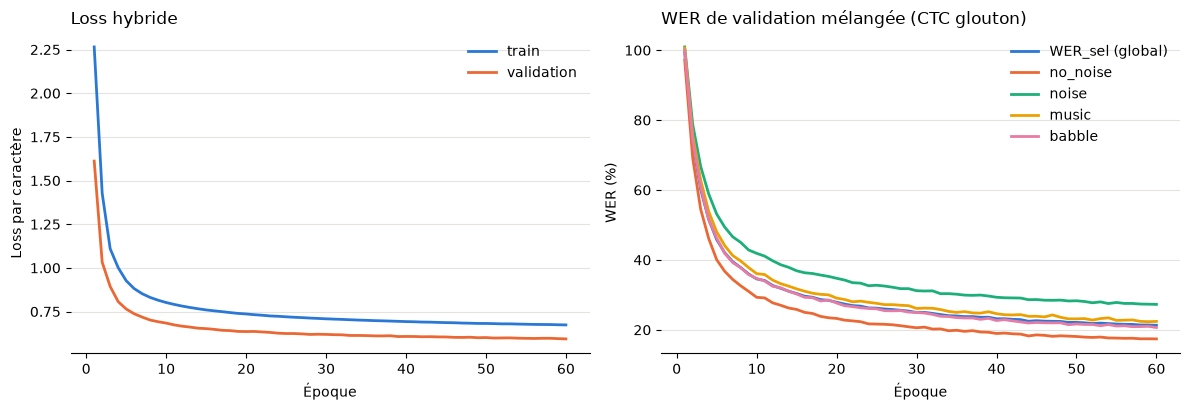

In [36]:
def plot_history(history):
    colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
    epochs = [entry["epoch"] + 1 for entry in history]
    categories = list(history[0]["val"]["categories"])

    figure, (loss_axis, wer_axis) = plt.subplots(1, 2, figsize=(12, 4.2))
    loss_axis.plot(epochs, [entry["train"]["loss"] for entry in history], color=colors[0], linewidth=2, label="train")
    loss_axis.plot(
        epochs,
        [entry["val"]["loss"] for entry in history],
        color=colors[1],
        linewidth=2,
        label="validation",
    )
    loss_axis.set_title("Loss hybride", loc="left")
    loss_axis.set_ylabel("Loss par caractère")

    wer_axis.plot(
        epochs,
        [100 * entry["val"]["wer_sel"] for entry in history],
        color=colors[0],
        linewidth=2,
        label="WER_sel (global)",
    )
    for category, color in zip(categories, colors[1:]):
        wer_axis.plot(
            epochs,
            [100 * entry["val"]["categories"][category] for entry in history],
            color=color,
            linewidth=2,
            label=category,
        )
    wer_axis.set_title("WER de validation mélangée (CTC glouton)", loc="left")
    wer_axis.set_ylabel("WER (%)")

    for axis in (loss_axis, wer_axis):
        axis.set_xlabel("Époque")
        axis.xaxis.get_major_locator().set_params(integer=True)
        axis.grid(axis="y", color="#e4e3df", linewidth=0.8)
        axis.set_axisbelow(True)
        axis.spines[["top", "right", "left"]].set_visible(False)
        axis.legend(frameon=False)
    figure.tight_layout()
    plt.show()


plot_history(history)

## 12. Test

Le meilleur modèle est évalué avec le beam search joint, sur chaque sous-ensemble et chaque condition de
`TEST_CONDITIONS` : parole propre, RIR réelles, WHAM! et DEMAND à chaque SNR. Les résultats sont
enregistrés dans `checkpoints/test_results.json` et mis en forme dans `checkpoints/test_results.md`. Au débit mesuré (environ 8 énoncés/s), compter 2 h 30.

In [ ]:
@torch.no_grad()
def test_condition(items, condition):
    model.eval()
    loader = make_loader(FrozenDataset(items, condition), items, cfg.beam_batch_seconds, shuffle=False)
    refs, hyps = [], []
    for batch in tqdm(loader, desc=condition.name, leave=False):
        wavs, wav_lens, tokens, token_lens = to_device(batch)
        decoded = [tok.decode(ids) for ids in joint_beam_search(model, wavs, wav_lens)]
        hyps += [corrector(text) for text in decoded] if corrector else decoded
        refs += references(tokens, token_lens)
    return jiwer.wer(refs, hyps)


def run_test():
    model.load_state_dict(torch.load(cfg.ckpt_dir / "best.pt", map_location=device)["model"])
    results = {
        subset: {condition.name: test_condition(items, condition) for condition in TEST_CONDITIONS}
        for subset, items in test_items.items()
    }
    (cfg.ckpt_dir / "test_results.json").write_text(json.dumps(results, indent=2))

    write_test_report(results, cfg.ckpt_dir / "test_results.md")
    return results


def write_test_report(results, path):
    """Écrit le tableau des WER (conditions × sous-ensembles) en Markdown."""
    subsets = list(results)
    lines = [
        "# Résultats de test",
        "",
        "WER (%) du meilleur modèle, beam search joint CTC / attention.",
        "",
        "| Condition | " + " | ".join(f"`{subset}`" for subset in subsets) + " |",
        "|---|" + "---:|" * len(subsets),
    ]
    for condition in TEST_CONDITIONS:
        cells = " | ".join(f"{100 * results[subset][condition.name]:.2f}" for subset in subsets)
        lines.append(f"| {condition.name} | {cells} |")
    path.write_text("\n".join(lines) + "\n")
    print(f"Résultats écrits dans {path}")


test_results = run_test()

## 13. Transcrire un fichier

In [37]:
def transcribe(path):
    """Transcrit un fichier audio à 16 kHz avec le modèle actuellement chargé."""
    model.eval()
    wav = load_audio(path).to(device)[None]
    ids = joint_beam_search(model, wav, torch.tensor([wav.size(1)], device=device))[0]
    text = tok.decode(ids)
    return corrector(text) if corrector else text


# Générateur sans graine : un énoncé différent à chaque exécution, même après un redémarrage du kernel.
picker = random.Random()
subset, example = picker.choice([(subset, item) for subset, items in test_items.items() for item in items])
hypothesis = transcribe(example["path"])
print(f"Énoncé    : {example['id']} ({subset}, {example['frames'] / cfg.sample_rate:.1f} s)")
print("Référence :", example["text"])
print("Modèle    :", hypothesis)
print(f"WER       : {jiwer.wer(example['text'], hypothesis):.2%}")

Énoncé    : 7127-75946-0024 (test-clean, 5.1 s)
Référence : MONSIEUR WAS THE ONLY ONE WHO DID NOT UNDERSTAND ANYTHING ABOUT THE MATTER
Modèle    : MONSIEUR WAS THE ONLY ONE WHO DID NOT UNDERSTAND ANYTHING ABOUT THE MATTER
WER       : 0.00%
